# Final model, decided after experimentation in q4_regression_experimentation

## Loading packages and data:

In [199]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [200]:
def build_df(filename, dayfirst=False):
    df = pd.read_csv(filename)
    
    # Time features
    df.dropna(inplace=True, subset=["Scheduled.Arrival", "Departure"]) # These can't be null, only one row where they are though
    df["Departure"] = pd.to_datetime(df["Departure"], dayfirst=dayfirst)
    df["Scheduled.Arrival"] = pd.to_datetime(df["Scheduled.Arrival"], dayfirst=dayfirst)
    df["Actual.Arrival"] = pd.to_datetime(df["Actual.Arrival"], dayfirst=dayfirst)
    df["Journey.Len"] = df["Scheduled.Arrival"] - df["Departure"]
    df["Delay.Len"] = df["Actual.Arrival"] - df["Scheduled.Arrival"]
    # HoursPastMidnight from HandlingDates_2026_Python.ipynb
    def hoursPastMidnight( datetime_series ):
        dt_at_midnight = datetime_series.dt.floor('D')
        td_series = (datetime_series - dt_at_midnight)
        hours_after_midnight = td_series.dt.total_seconds() / 3600
        return( hours_after_midnight )
    df["ToD.Departure"] = hoursPastMidnight(df["Departure"])
    df["TimeFromMidday"] = (df["ToD.Departure"] - 12)/12
    df["PeakHours"] = df["ToD.Departure"].apply(lambda x: 1 if x>6 and x<10 or x>17 and x<19 else 0)
    # Make timedeltas into minutes
    df["Journey.Len"] = df["Journey.Len"].apply(lambda x: x.total_seconds()/60)
    df["Delay.Len"] = df["Delay.Len"].apply(lambda x: x.total_seconds()/60)
    # !!! Delay.Len will be NaN when a journey is cancelled !!!
    # So any dropna() will remove all cancelled journeys, better to find a filler value
    df["Delay.Len"] = df["Delay.Len"].fillna(0)
    df["DelayRatio"] = df["Delay.Len"]/df["Journey.Len"]

    # Use log(Price)
    df["Price"] = np.log(df["Price"])

    # Make Refund.Request binary
    df["Refund.Request"] = df["Refund.Request"].apply(lambda x: 1 if x=="Yes" else 0)

    # Group railcard because disabled railcard leads to separation
    df["Railcard"] = df["Railcard"].fillna("No railcard")
    df["Railcard2"] = df["Railcard"].apply(lambda x: "SeniorOrDisabled" if x in ("Senior","Disabled") else x)

    df["DelayedNotCancelled"] = (df["Journey.Status"]=="Delayed").astype(int)
    return df

def train_val_test_split(df, split=[0.9, 1]):
    index = list(df.index)
    np.random.seed(42)
    np.random.shuffle(index)
    cutoff = [int(split[0]*len(index)), int(split[1]*len(index))]
    train_index, val_index, test_index = index[:cutoff[0]], index[cutoff[0]:cutoff[1]], index[cutoff[1]:]
    return df.loc[train_index], df.loc[val_index], df.loc[test_index]

def plot_model_summary(df, predictions, labels=["No Refund Request", "Refund Request"]):
    y = df["Refund.Request"]
    
    fig, axs = plt.subplots(2,2, figsize=(12,10), layout="constrained")
    axs[0,0].boxplot([predictions[y==0], predictions[y==1]], tick_labels=labels)
    axs[0,0].set_ylabel("Predicted Probability")
    
    sns.kdeplot(predictions[y==0], label=labels[0], ax=axs[0,1])
    sns.kdeplot(predictions[y==1], label=labels[1], ax=axs[0,1])
    axs[0,1].set_xlabel("Predicted Probability")
    axs[0,1].legend()
    
    mask_cancelled = df["Journey.Status"]=="Cancelled"
    mask_delayed = df["Journey.Status"]=="Delayed"
    mask_ontime = df["Journey.Status"]=="On Time"

    from sklearn.metrics import RocCurveDisplay
    from sklearn.calibration import CalibrationDisplay
    for mask in [mask_cancelled, mask_delayed, mask_cancelled|mask_delayed]:
        RocCurveDisplay.from_predictions(y[mask], predictions[mask], ax=axs[1,0])
        axs[1,0].plot([0, 1], [0, 1], "k--")
        
        CalibrationDisplay.from_predictions(y[mask], predictions[mask], ax=axs[1,1])    
    plt.show()

In [201]:
df = build_df("MavenRail.csv")
df = df[df["Journey.Status"]!="On Time"] # we are not training on On Time journeys
df_train, df_val, _ = train_val_test_split(df, split=[0.9, 1])

## Define and fit model:

Optimization terminated successfully.
         Current function value: 0.360744
         Iterations 9
                            Logit Regression Results                           
Dep. Variable:     Q("Refund.Request")   No. Observations:                 3708
Model:                           Logit   Df Residuals:                     3685
Method:                            MLE   Df Model:                           22
Date:                 Mon, 23 Nov 2026   Pseudo R-squ.:                  0.3809
Time:                         12:42:47   Log-Likelihood:                -1337.6
converged:                        True   LL-Null:                       -2160.6
Covariance Type:             nonrobust   LLR p-value:                     0.000
                                                                        coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------

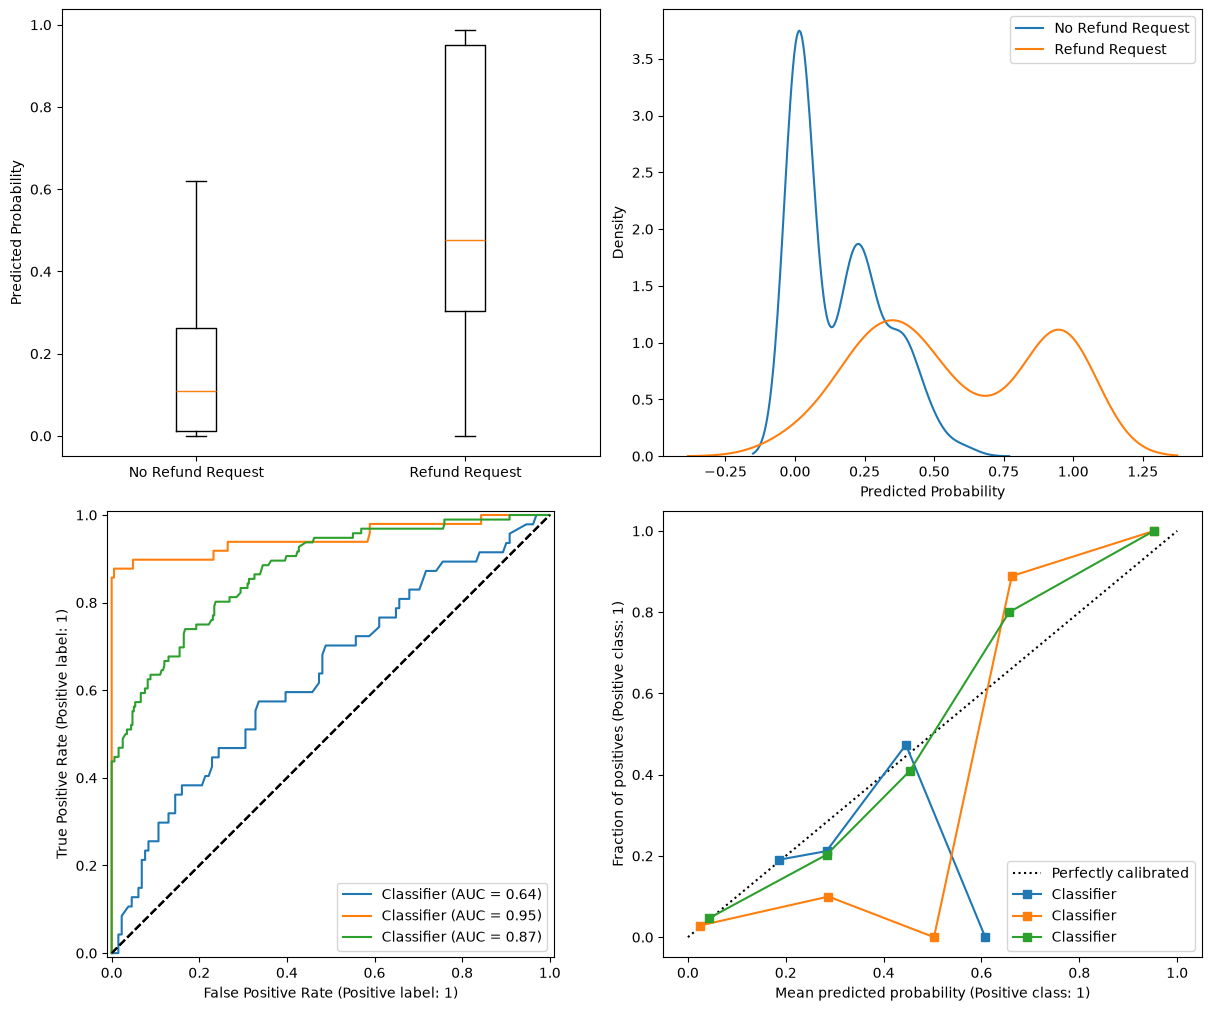

In [202]:
formula = 'Q("Refund.Request") ~ ' + \
        'Q("Journey.Status")*' + \
        '(Q("Payment.Method")+Q("Ticket.Type")+Q("TimeFromMidday")+Q("PeakHours")+' + \
        'Q("Price")+Q("Railcard2")+Q("Journey.Len"))+Q("DelayRatio")'

model = smf.logit(formula, data=df_train).fit(maxiter=200)
predictions = model.predict(df_val)

print(model.summary())
model.save("logreg_status_interaction.pkl")
plot_model_summary(df_val, predictions)

In [203]:
import sklearn.metrics as sk_metrics
mask = df_val["Journey.Status"]=="Delayed"
print(sk_metrics.brier_score_loss(df_val["Refund.Request"], predictions))
print(sk_metrics.brier_score_loss(df_val.loc[mask, "Refund.Request"], predictions[mask]))
print(sk_metrics.brier_score_loss(df_val.loc[~mask, "Refund.Request"], predictions[~mask]))

0.10366496915296701
0.03960760233116984
0.18787521542431837


## Predict on test set (ToPredict_with_refund.csv)

In [204]:
# Date is formatted differently in the test csv, so needs dayfirst=True
df_test = build_df("ToPredict_with_refund.csv", dayfirst=True)

In [205]:
# Make predictions dictionary
predict_dict = {}

# Deterministically set refund=0 when status=="On Time"
ontime_mask = df_test["Journey.Status"]=="On Time"
for i in df_test.index[ontime_mask]:
    predict_dict[i] = np.float64(0)

# Use model only on the remaining cases
model_predictions = model.predict(df_test.loc[~ontime_mask])
predict_dict.update(dict(model_predictions))

# Join predictions to DataFrame
df_predict = pd.DataFrame({"index":list(predict_dict.keys()),
                          "predicted_refund":list(predict_dict.values())}).set_index("index")
df_test = df_test.join(df_predict)

In [206]:
print(df_test[["Refund.Request", "predicted_refund"]])

   Refund.Request  predicted_refund
0               0          0.000000
1               0          0.000000
2               0          0.957286
3               0          0.051690
4               0          0.370321
5               0          0.397306
6               0          0.959198
7               1          0.434405


In [207]:
# Using Brier Score to compare performance on test dataset
import sklearn.metrics as sk_metrics
print("Model:\n", 
      sk_metrics.brier_score_loss(df_test["Refund.Request"], df_test["predicted_refund"]))
print("Predicting 50% chance:\n",
      sk_metrics.brier_score_loss(df_test["Refund.Request"], [0.5]*df_test.shape[0]))

df_og = pd.read_csv("MavenRail.csv")
baseline_rate = np.mean(df_og["Refund.Request"]=="Yes")
print("Predicting baseline rate:\n",
      sk_metrics.brier_score_loss(df_test["Refund.Request"], [baseline_rate]*df_test.shape[0]))

Model:
 0.30675202777573757
Predicting 50% chance:
 0.25
Predicting baseline rate:
 0.11735234333868226
